In [1]:
import math
import numpy as np
import tensorflow as tf

from plotly.subplots import make_subplots
import plotly.graph_objects as go

from tf_ofcs.components import *
from tf_ofcs.datatypes import Signal, TensorCompatible
from tf_ofcs.utils import symbol_mapping_to_gray, psk_constellation, dbm_to_w, to_tensor
from tf_ofcs.plot import *
from tf_ofcs.reference_systems import IQSystem

from typing import Optional, Any

2025-03-13 19:49:43.996404: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-03-13 19:49:44.087516: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-03-13 19:49:44.087548: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-03-13 19:49:44.094107: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-03-13 19:49:44.118117: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-03-13 19:49:44.119041: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [2]:
Component.trace_debug_enabled_by_default = False

qam4_mapping = tf.constant([
    [-1.0, -1.0], [-1.0, 1.0],
    [ 1.0, -1.0], [ 1.0, 1.0]
])

qam16_mapping = symbol_mapping_to_gray([
    [-1.0,  1.0], [-1.0,  1/3], [-1.0, -1/3], [-1.0, -1.0],
    [-1/3, -1.0], [-1/3, -1/3], [-1/3,  1/3], [-1/3,  1.0],
    [ 1/3,  1.0], [ 1/3,  1/3], [ 1/3, -1/3], [ 1/3, -1.0],
    [ 1.0, -1.0], [ 1.0, -1/3], [ 1.0,  1/3], [ 1.0,  1.0]
])

bits_per_symbol, symbol_mapping = 2, symbol_mapping_to_gray(psk_constellation(2, phase_offset=0.0))

system = IQSystem(
    n_taps=25,
    bits_per_symbol=bits_per_symbol,
    mapping=symbol_mapping,
    enable_phase_noise=True,
    carrier_phase_recovery="decision_directed"
)
ber_tester = BERTester(system, rng=system.rng)

system.set_channel(Composition([
    PadSignal(0.125),
    OpticalFiber(
        attenuation=[0.22],
        length=[40.0],
        chromatic_dispersion=[17.0],
        eff_non_linear_coeff=[1.76],
        central_frequency=193.414e12,
        step_count=1,
        enable_nonlinear_effects=True,
        name="fiber"
    ),
    PadSignal(0.125, unpad=True),
    OpticalAWGN(relative_db=[-30.0], rng=system.rng, name="channel_noise"),
], name="channel"))

system_params = {
    "bit_sequence_generator__length": tf.constant(1024),
    "lpf__symbol_rate": tf.constant(21e9),
    "laser__linewidth": tf.constant([1e6]),
    "local_oscillator__linewidth": tf.constant([1e6]),
    "decision_directed_phase_recovery__window_length": tf.constant(4),
    "viterbi_viterbi_phase_recovery__window_length": tf.constant(1)
}

In [3]:
def plot(chromatic_dispersion, eff_non_linear_coeff, fiber_length, attenuation, osnr, rolloff_factor):
    params = system_params
    params["fiber__chromatic_dispersion"] = to_tensor([chromatic_dispersion])
    params["fiber__eff_non_linear_coeff"] = to_tensor([eff_non_linear_coeff])
    params["fiber__length"] = to_tensor([fiber_length])
    params["fiber__attenuation"] = to_tensor([attenuation])
    params["channel_noise__relative_db"] = to_tensor([-osnr])
    params["lpf__rolloff_factor"] = to_tensor(rolloff_factor)

    system.rng.reset_from_seed(1)

    system.setup(system.channel.substitute, params)
    system.trace(system.bitseq_generator.trace(**params), **params)

    input_signal = system.find_child("bit_sequence_generator").output

    fig = make_subplots(
        rows=3,
        cols=1,
        subplot_titles=(
            "Bit sequence",
            "Encoded signal",
            "Optical signal"
        ),
        vertical_spacing = 0.05
    )

    plot_bitseq(input_signal, fig, 0, row=1, col=1, label="Input sequence")
    plot_bitseq(system.output, fig, row=1, col=1, label="Output sequence")

    offset_signal = TruncateSignal(left=0.5 / (system.data_rate / float(system.bits_per_symbol)), mode="time")

    encoded = system.find_child("qam_symbol_encoder").output
    encoded = offset_signal(encoded)

    before_filter = system.find_child("before_filter").output
    before_filter = offset_signal(Signal(
        samples=tf.complex(tf.abs(tf.math.reduce_sum(system.rx_filter.taps)), 0.0) * before_filter.samples,
        timing=before_filter.timing
    ))
    
    plot_envelope(encoded, fig, row=2, col=1, label="Encoded signal")
    plot_envelope(system.find_child("receiver").output, fig, row=2, col=1, label="Received signal")
    plot_envelope(before_filter, fig, row=2, col=1, label="Received signal (before filter)")
    
    plot_power(system.find_child("transmitter").output, fig, row=3, col=1, label="Transmitted signal")
    plot_power(system.find_child("channel").output, fig, row=3, col=1, label="Signal after fiber")

    fig.update_layout(
        autosize=True,
        height=1000
    )

    return fig


import ipywidgets

ipywidgets.interact(
    plot,
    chromatic_dispersion=(-30.0, 30.0, 1.0),
    eff_non_linear_coeff=(0.0, 20.0, 1.0),
    fiber_length=(0.0, 65.0, 1.0),
    attenuation=(0.0, 0.4, 0.01),
    osnr=(-10.0, 80.0, 1.0),
    rolloff_factor=(0.0, 1.0, 0.01)
)

interactive(children=(FloatSlider(value=0.0, description='chromatic_dispersion', max=30.0, min=-30.0, step=1.0…

<function __main__.plot(chromatic_dispersion, eff_non_linear_coeff, fiber_length, attenuation, osnr, rolloff_factor)>

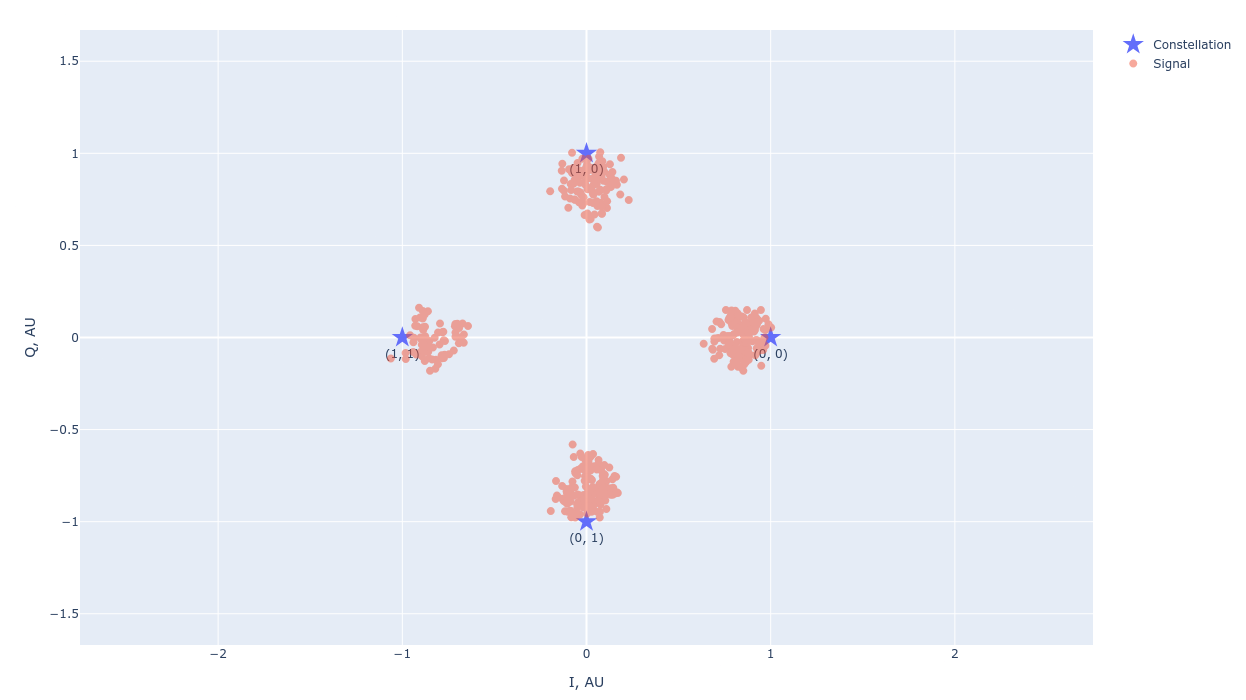

In [4]:
annotate_constellation = True
annotations = []

if annotate_constellation:
    for i, symbol in enumerate(symbol_mapping):
        bit_string = ', '.join(
            tuple(
                bin(i)[2:].zfill(
                    int(bits_per_symbol)
                )
            )
        )
    
        annotations.append(f"({bit_string})")

fig = plot_iq_constellation(
    tf.expand_dims(symbol_mapping, 0),
    label="Constellation",
    mode="markers+text",
    text=annotations,
    textposition="bottom center",
    marker=dict(size=16, symbol="star")
)

fig = plot_iq_constellation(
    ComplexToIQ()(system.find_child("receiver").output),
    fig,
    iq_units=(1.0, "AU"),
    label="Signal",
    marker=dict(size=8, opacity=1.0),
    opacity=0.5,
    mode="markers"
)

fig.update_yaxes(scaleanchor='x', range=[-1.5, 1.5])
fig.update_xaxes(range=[-1.5, 1.5])
fig.update_layout(width=800, height=700, margin=dict(t=30, b=30))
fig.show()

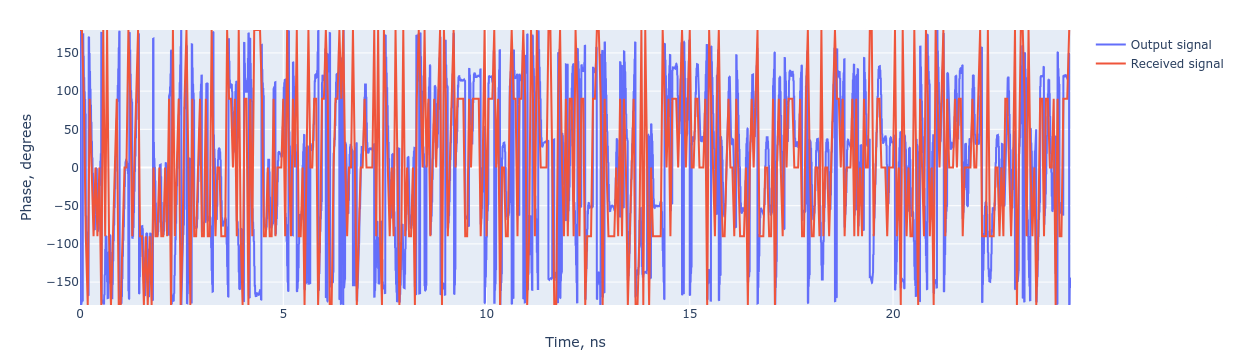

In [18]:
fig = plot_phase(system.find_child("modulator").output, label="Output signal")
plot_phase(system.find_child("receiver").output, fig, label="Received signal")

fig.update_yaxes(range=[-180.0, 180.0])
fig.update_layout(autosize=True, height=600, margin=dict(t=30, b=30))

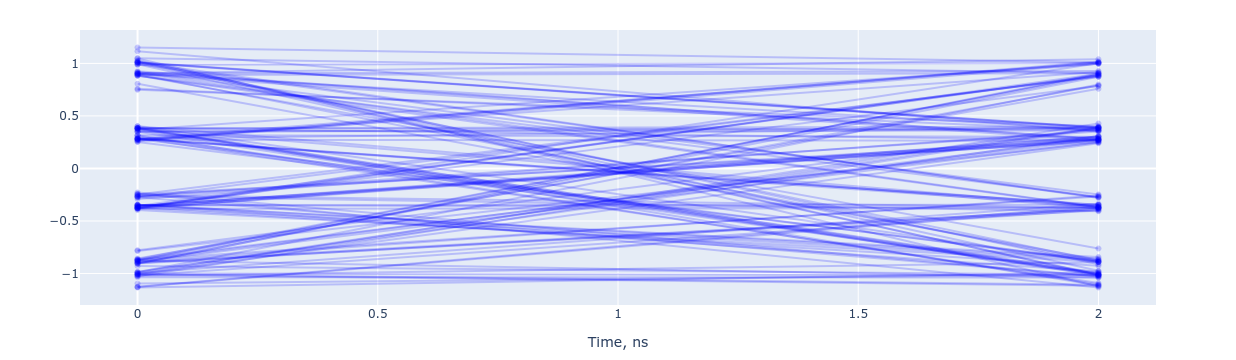

In [25]:
fig = go.Figure(layout=go.Layout(xaxis={"title": "Time, ns"}, showlegend=False))
for signal in system.find_child("receiver").output:
    plot_eye_diagram(signal, system.data_rate / bits_per_symbol, fig, line={"color": "rgba(0, 0, 255, 0.2)"})
fig.update_layout(autosize=True, height=600, margin=dict(t=30, b=30))
fig.show()

In [21]:
%time ber_tester(tf.constant(128), **system_params, ber_tester__n_iterations=tf.constant(5), ber_tester__batch_size=tf.constant(1000))

2025-03-06 18:45:23.449888: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 800000000 exceeds 10% of free system memory.
2025-03-06 18:45:23.659802: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 400000000 exceeds 10% of free system memory.
2025-03-06 18:45:23.888070: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 800000000 exceeds 10% of free system memory.
2025-03-06 18:45:24.772956: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 800000000 exceeds 10% of free system memory.
2025-03-06 18:45:24.993251: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 800000000 exceeds 10% of free system memory.


CPU times: user 11min 8s, sys: 1min 48s, total: 12min 56s
Wall time: 3min 56s


<tf.Tensor: shape=(), dtype=float32, numpy=0.0006640625>